# Practical Session of Week 4 - Review + Correlation between Variables
This notebook contains the exercises and concepts of **Data Science Practice discipline**.  
Throughout the notebook, we will:

- Review key concepts of quantitative features in rectangular data.
- Solve guided examples and exercises to consolidate learning.

The purpose of this notebook is to consolidate knowledge previously discussed and deepen the EDA techniques through knowledge of associations/correlations between variables.

# Part 1: Review
In this section, we will explore fundamental concepts of quantitative features in rectangular data.

- Central Tendency: Mean, Median, Mode
- Dispersion: Range, IQR, Variance, STD
- Frequency Tables and Categorical Feature Summaries
- Notion of A Distribution
- Population vs Sample

# Part 2: Linear Correlations
- Correlation between variables
- Dispersion charts

Importing Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Part 1 - Review for the next week test

### Exercise 1
Create a DataFrame called `df_notas` with 50 rows, containing a `grade` column with random integer values **between 0 and 20**.

In [79]:
np.random.seed(42)
df_notas = pd.DataFrame({'grades': np.random.randint(0, 21, 50)})
df_notas.head()

,grades
0,6
1,19
2,14
3,10
4,7


### Exercise 2
Add to DataFrame `df_notas` A column called `status` that classifies each student as `Pass` if the **grade is > = 10** or `Fail` otherwise. Try to do this without using loops with `np.where`.

In [80]:
# add status column
#usa o np.where para localizar uma condicao
df_notas['status'] = np.where(df_notas['grades'] >= 10, 'Pass', 'Fail')
df_notas.head()

,grades,status
0,6,Fail
1,19,Pass
2,14,Pass
3,10,Pass
4,7,Fail


In [81]:
a = pd.Series([1,2,3,1,5,6,1,1,3,4,5])
np.where(a == 1, 'yes', 'no')


array(['yes', 'no', 'no', 'yes', 'no', 'no', 'yes', 'yes', 'no', 'no',
       'no'], dtype='<U3')

In [82]:
df_notas['status'].value_counts()

,count
status,
Pass,29
Fail,21


<Axes: xlabel='status'>

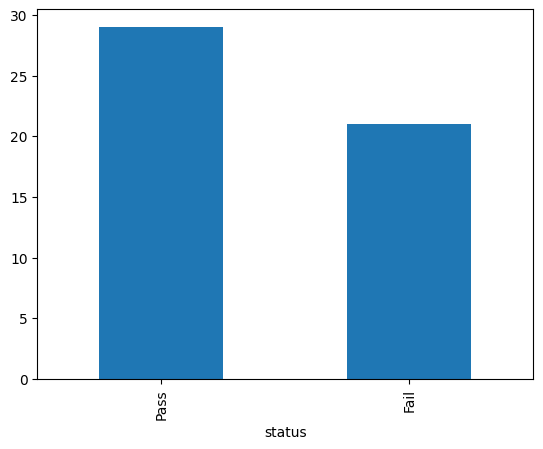

In [83]:
df_notas['status'].value_counts().plot(kind='bar')

### Exercise 3
Calculate the average, median and quartis (q1, q2, q3) of the grades.

In [ ]:
df_notas.describe()

,grades
count,50.000000
mean,10.960000
std,6.343758
min,0.000000
25%,6.000000
50%,11.000000
75%,17.000000
max,20.000000


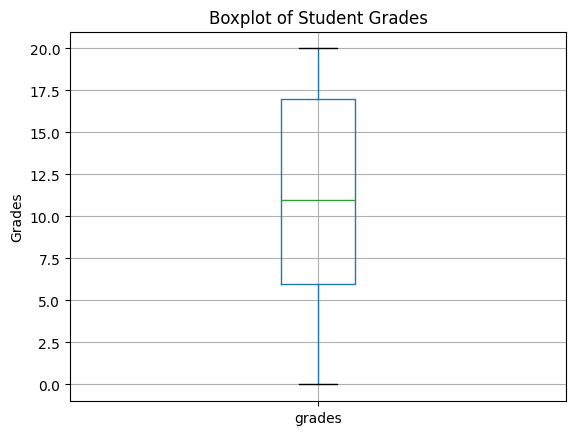

In [ ]:
df_notas.boxplot(column='grades')
plt.ylabel('Grades')
plt.title('Boxplot of Student Grades')
plt.show()

### Exercise 4
Create a histogram of grades with 10 bins.

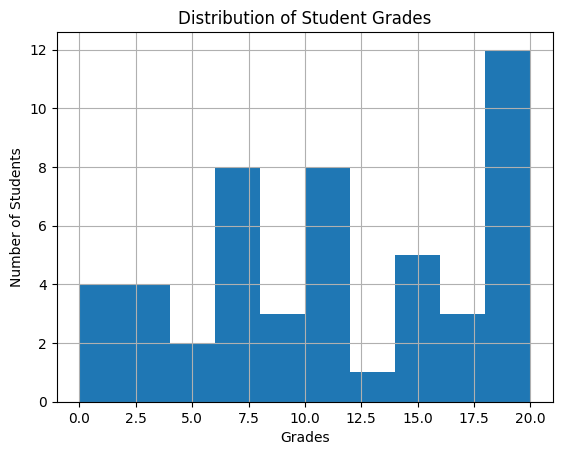

In [ ]:
#definindo os bins
df_notas.hist(bins=10)
plt.xlabel('Grades')
plt.ylabel('Number of Students')
plt.title('Distribution of Student Grades')
plt.show()

### Exercise 5
Create a grades boxplot to analyze the distribution.

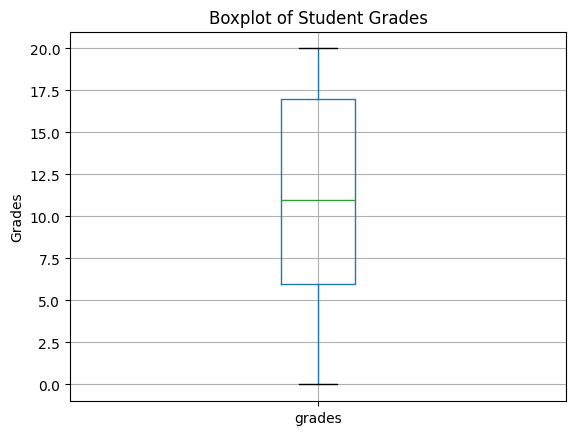

In [ ]:
# grades boxplot to analyze distribution
df_notas.boxplot(column='grades')
plt.ylabel('Grades')
plt.title('Boxplot of Student Grades')
plt.show()

### Exercise 6
Create a DataFrame `df_salarios` with 100 random salaries between 1200 and 8000.

In [ ]:
np.random.seed(42)
df_salarios = pd.DataFrame({'salary': np.random.randint(1200, 8001, 100)})
df_salarios.head()

,salary
0,2060
1,6590
2,6426
3,6391
4,4972


### Exercise 7
Add to DataFrame `df_salarios` a `salary_range` column that classifies each salary in:
`Low` (<Q1), `Medium` (between Q1 and Q3) and `High` (> Q3).

In [ ]:
# Calculate quartiles
q1 = df_salarios['salary'].quantile(0.25)
q3 = df_salarios['salary'].quantile(0.75)

# using loc to classify Salaries according to quartiles intervals
df_salarios.loc[df_salarios['salary'] < q1, 'salary_range'] = 'Low'
df_salarios.loc[(df_salarios['salary'] >= q1) & (df_salarios['salary'] <= q3), 'salary_range'] = 'Medium'
df_salarios.loc[df_salarios['salary'] > q3, 'salary_range'] = 'High'
df_salarios

,salary,salary_range
0,2060,Low
1,6590,High
2,6426,High
3,6391,High
4,4972,Medium
...,...,...
95,2216,Low
96,7639,High
97,1537,Low
98,2078,Low


In [ ]:
df_salarios['salary_range'].value_counts()

,count
salary_range,
Medium,50
Low,25
High,25


**Alternatively, you can use `pd.cut`**

In [ ]:
# Calculate quartiles
q1 = df_salarios['salary'].quantile(0.25)
q3 = df_salarios['salary'].quantile(0.75)

# pd.cut to classify Salaries
df_salarios['salary_range'] = pd.cut(df_salarios['salary'],
                                      bins=[0, q1, q3, np.inf],
                                      labels=['Low', 'Medium', 'High'])

df_salarios


,salary,salary_range
0,2060,Low
1,6590,High
2,6426,High
3,6391,High
4,4972,Medium
...,...,...
95,2216,Low
96,7639,High
97,1537,Low
98,2078,Low


### Exercise 8
Create a histogram and a boxplot of salaries.

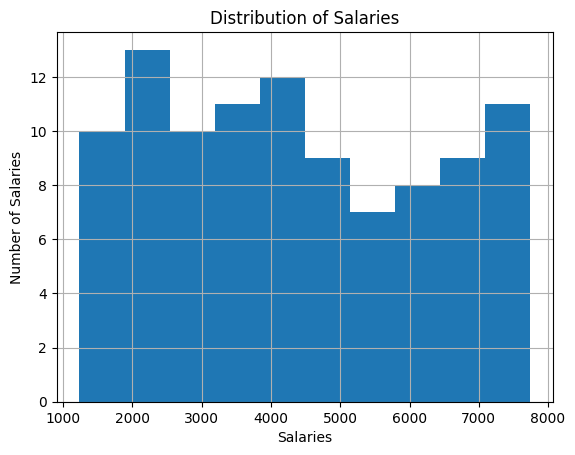

In [ ]:
#histogram
df_salarios.hist(bins=10)
plt.xlabel('Salaries')
plt.ylabel('Number of Salaries')
plt.title('Distribution of Salaries')
plt.show()

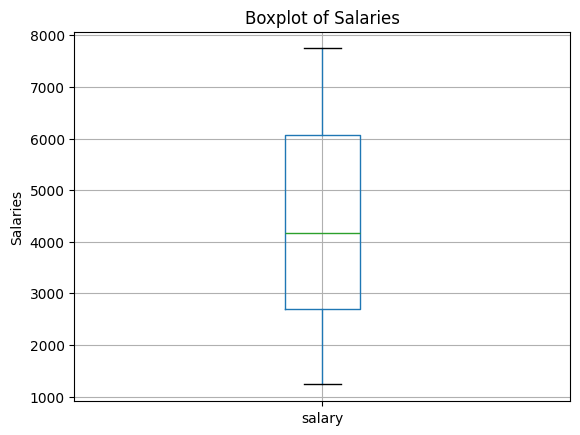

In [ ]:
#boxplot
df_salarios.boxplot(column='salary')
plt.ylabel('Salaries')
plt.title('Boxplot of Salaries')
plt.show()

### Exercise 9
Create two DataFrames: `df_clients` (with `client_id` and `name`) and` df_purchases` (with `client_id` and `value` of purchase). Finally, merge the DataFrames (`pd.merge`).

In [ ]:
df_clients = pd.DataFrame({
    'client_id': [1, 2, 3, 4, 5],
    'name': ['Alice', 'Bob', 'Charlie', 'David', 'Eva'],
    'age': [28, 34, 29, 42, 23]})

df_clients

,client_id,name,age
0,1,Alice,28
1,2,Bob,34
2,3,Charlie,29
3,4,David,42
4,5,Eva,23


In [ ]:
df_purchases = pd.DataFrame({
    'client_id': [1, 2, 1, 3, 4, 2, 5, 3],
    'value': [250, 450, 300, 150, 500, 200, 700, 100]})

df_purchases

,client_id,value
0,1,250
1,2,450
2,1,300
3,3,150
4,4,500
5,2,200
6,5,700
7,3,100


In [ ]:
df_merged = pd.merge(df_clients, df_purchases, on='client_id', how='inner')
df_merged

,client_id,name,age,value
0,1,Alice,28,250
1,1,Alice,28,300
2,2,Bob,34,450
3,2,Bob,34,200
4,3,Charlie,29,150
5,3,Charlie,29,100
6,4,David,42,500
7,5,Eva,23,700


| `how` | O que faz |
|---|---|
| `'inner'` | Apenas IDs que existem **nas duas tabelas** |
| `'left'` | Mantém **todos os clientes** de `df_clients` |
| `'right'` | Mantém **todas as compras** de `df_purchases` |
| `'outer'` | Mantém **todos os IDs das duas tabelas** |

**Alternatively, you can do like that**

In [ ]:
df_merged = df_clients.merge(df_purchases, on='client_id', how='inner')
df_merged

,client_id,name,age,value
0,1,Alice,28,250
1,1,Alice,28,300
2,2,Bob,34,450
3,2,Bob,34,200
4,3,Charlie,29,150
5,3,Charlie,29,100
6,4,David,42,500
7,5,Eva,23,700


### Exercise 10
In the resulting DataFrame of the merge, create a new column called `with_discount` Apply **10% discount** to the purchase value.

In [ ]:
df_merged['with_discount'] = df_merged['value'] * 0.9
df_merged

,client_id,name,age,value,with_discount
0,1,Alice,28,250,225.0
1,1,Alice,28,300,270.0
2,2,Bob,34,450,405.0
3,2,Bob,34,200,180.0
4,3,Charlie,29,150,135.0
5,3,Charlie,29,100,90.0
6,4,David,42,500,450.0
7,5,Eva,23,700,630.0


## Part 2 - Linear Correlations

In [ ]:
# install scipy if it is not installed already
!pip install scipy

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

### Exercise 1
Create two x and y vectors with 100 data points (`y = 2x + noise`). Scatter plot the data.

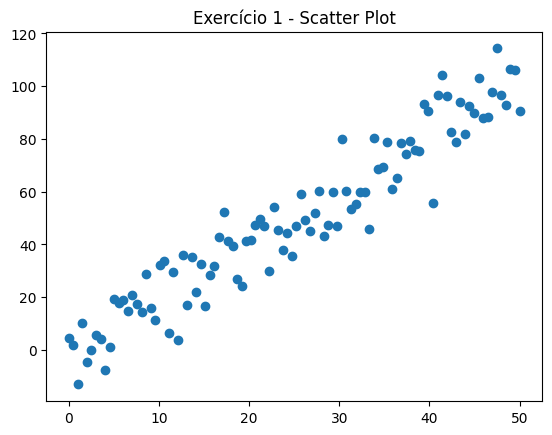

In [ ]:
x = np.linspace(0, 50, 100)
y = 2*x + np.random.normal(0, 10, 100)
plt.scatter(x, y)
plt.title("Exercício 1 - Scatter Plot")
plt.show()


### Exercise 2
Use seaborn.Pairplot to view relationships between 4 random variables.

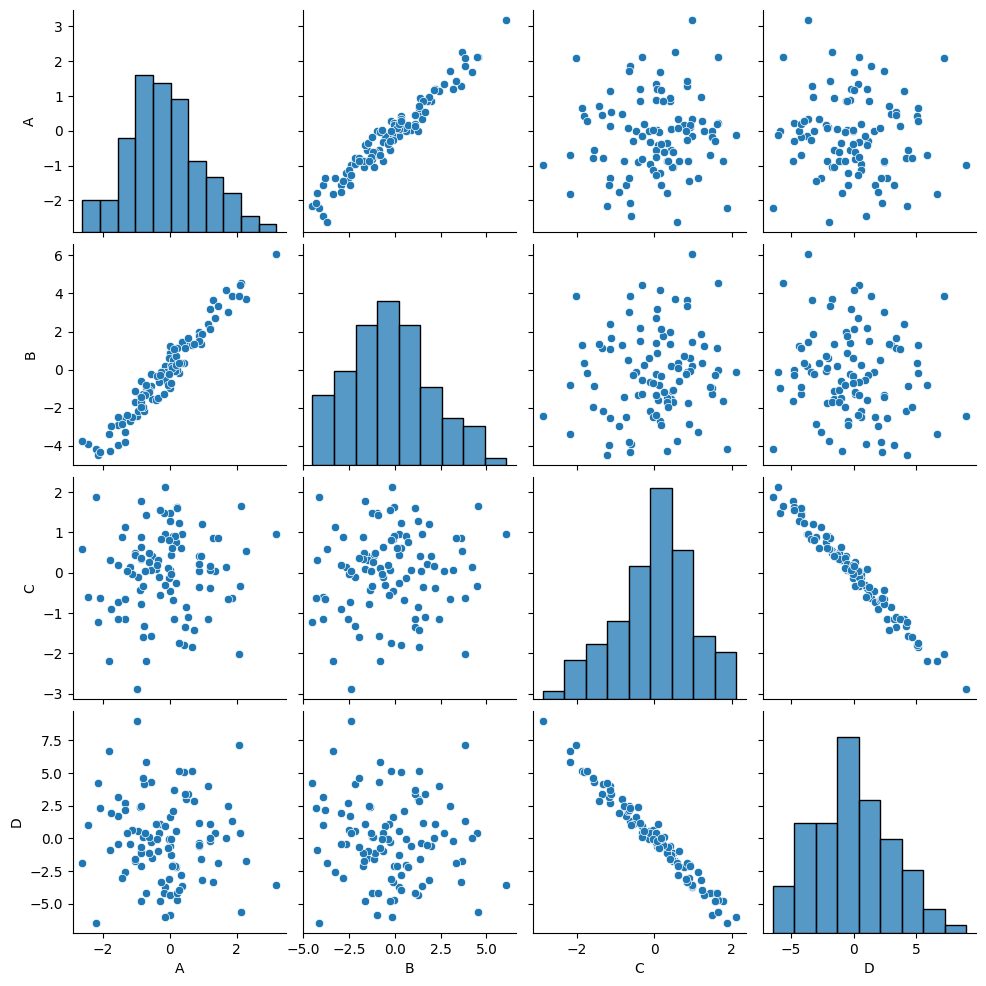

In [ ]:
df = pd.DataFrame(np.random.randn(100, 4), columns=list("ABCD"))
# df
# Create A Linear Relation Between A And B
df["B"] = df["A"] * 2 + np.random.normal(0, 0.5, 100)
# Create Linear Relation Between C and D
df["D"] = df["C"] * -3 + np.random.normal(0, 0.5, 100)
sns.pairplot(df)

### Exercise 3
Generate a linear association (`y = 3x + noise`) and **scatter plott with trend line**.

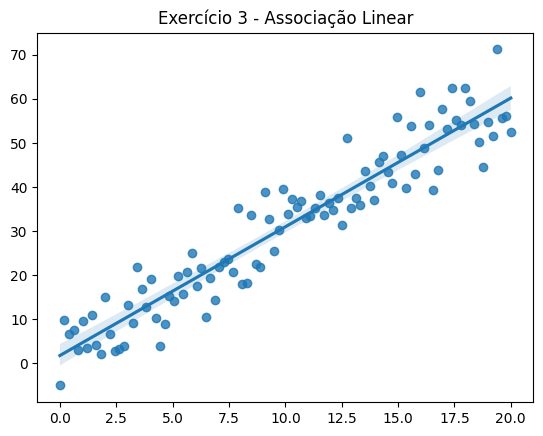

In [ ]:
x = np.linspace(0, 20, 100)
y = 3*x + np.random.normal(0, 5, 100)
sns.regplot(x=x, y=y, ci=98)
plt.title("Exercício 3 - Associação Linear")
plt.show()

### Exercise 4
Generate a nonlinear association (`y = x^2 + noise`) and a scatter plot.

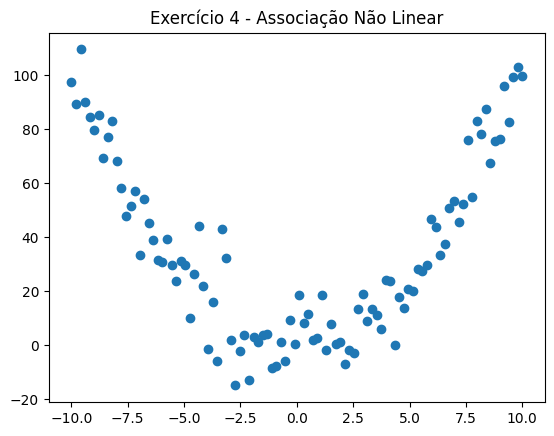

In [ ]:
x = np.linspace(-10, 10, 100)
y = x**2 + np.random.normal(0, 10, 100)
plt.scatter(x, y)
plt.title("Exercício 4 - Associação Não Linear")
plt.show()

### Exercise 5
Calculate **Pearson's correlation** between x and y of **Exercise 3**. Explain the result.

In [ ]:
pearson_corr = stats.pearsonr(x, y)
print(pearson_corr)

# we can conclude that there is no significant linear correlation between x and y
# because the correlation coefficient is very close to 0
# and the p-value is much greater than 0.05 which indicates that we fail to reject the null hypothesis of no correlation.

PearsonRResult(statistic=np.float64(0.010757677767153133), pvalue=np.float64(0.9154019864542098))


### Exercise 6
Calculate the `Spearman Correlation` between X and Y of `Exercise 4`. Explain the result.

In [ ]:
spearman_corr = stats.spearmanr(x, y)
spearman_corr
# given the result SignificanceResult(statistic=np.float64(-0.0016081608160816079), pvalue=np.float64(0.987330580098831)) we can also conclude that there is no significant monotonic correlation between x and y
# because the correlation coefficient is very close to 0
# and the p-value is much greater than 0.05.
# in simple terms when the p-value is high, it means that the observed correlation could easily occur by random chance,
# so we cannot confidently say there is a real association between the variables.

SignificanceResult(statistic=np.float64(-0.0016081608160816079), pvalue=np.float64(0.987330580098831))

### Exercise 7
Compare **Pearson** and **Spearman** in quadratic data.

In [ ]:
x = np.linspace(-5, 5, 100)
y = x**2
pearson = stats.pearsonr(x, y)
spearman = stats.spearmanr(x, y)
pearson, spearman
# Explain The Results
# In Quadratic Data, Pearson Correlation may be Low or Zero Because It measures Linear Relationships, While Spearman Correlation Captures The Monotonic Relationship, Resulting in A Higher Value.

(PearsonRResult(statistic=np.float64(-2.0816681711721685e-17), pvalue=np.float64(1.0)),
 SignificanceResult(statistic=np.float64(-0.002646479021386217), pvalue=np.float64(0.9791519704231377)))

### Exercise 8
Simulate data with **weak correlation (high noise)**. Show scatter plot.

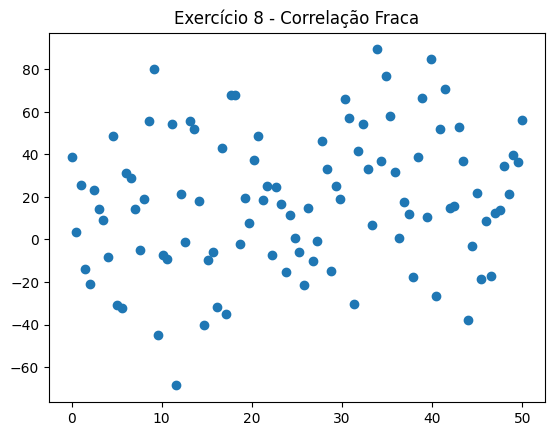

In [ ]:
x = np.linspace(0, 50, 100)
y = 0.5*x + np.random.normal(0, 30, 100)
plt.scatter(x, y)
plt.title("Exercício 8 - Correlação Fraca")
plt.show()

In [ ]:
np.random.normal(0, 30, 100)

array([ 26.21349123,  23.04371505,  93.14602285,  10.4220791 ,
        77.80714512,  12.36655207,  -2.48552744, -11.19495547,
        45.29177395,  49.21510179,  17.99351568,  34.00640324,
       -38.31661398, -46.46339468,  37.38980657,  -3.80434494,
        22.47907252, -21.5186385 ,  49.70965409, -46.21256016,
       -41.56755259,  43.32934751, -78.29525379,  11.35706604,
        -3.21977987, -22.07855758,  -5.99819546, -25.42570479,
        46.26767838,  54.13491265, -20.5721276 ,   8.26574632,
       -39.75229413,  32.19156477,  31.41027524,  -8.85786698,
         0.50655175,  -2.81296349, -48.55373501,  46.38012443,
       -23.00859717, -22.80447817,  -4.51259563,  29.86645756,
       -17.73909645, -58.56555664, -26.60994182,  12.72421257,
        65.69250863, -37.79759899, -38.89505302, -45.37786503,
       -49.10174974,  36.1707438 ,  44.84065726,   5.33267681,
       -14.03138316,  53.73431361,   5.21724125,  32.68310128,
       -15.49346825,   1.32731563, -37.12024936,  18.87

### Exercise 9
Simulate data with **moderate correlation**.

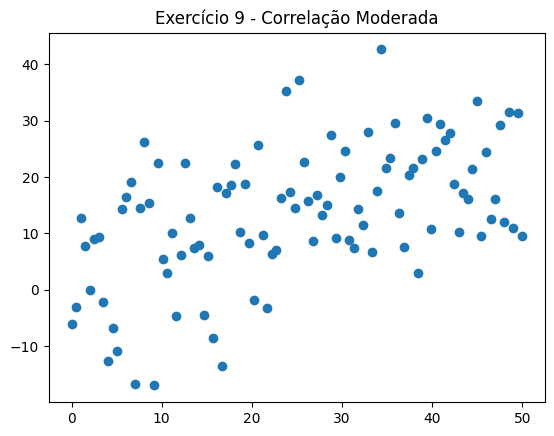

In [ ]:
x = np.linspace(0, 50, 100)
y = 0.5*x + np.random.normal(0, 10, 100)
plt.scatter(x, y)
plt.title("Exercício 9 - Correlação Moderada")
plt.show()

### Exercise 10
Simulate data with **strong correlation**.

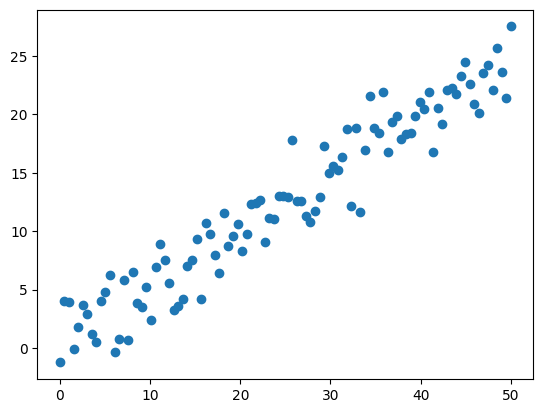

In [ ]:
x = np.linspace(0, 50, 100)
y = 0.5*x + np.random.normal(0, 2, 100)
plt.scatter(x, y)

### Exercise 11
Test significance of **Pearson's correlation** in data with 20 data points.

In [ ]:
x = np.linspace(0, 10, 20)
y = 2*x + np.random.normal(0, 5, 20)
stats.pearsonr(x, y)

# given spearman_corr = stats.spearmanr(x, y)
spearman_corr
# we can conclude that there is a significant linear correlation between x and y
# because the correlation coefficient is moderately high (0.66)
# and the p-value is less than 0.05 which indicates that we reject the null hypothesis of no correlation.

SignificanceResult(statistic=np.float64(-0.0016081608160816079), pvalue=np.float64(0.987330580098831))

### Exercise 12
Test significance of **Pearson's correlation** in data with 200 data points.

In [ ]:
x = np.linspace(0, 10, 200)
y = 0.2*x + np.random.normal(0, 5, 200)
stats.pearsonr(x, y)

# we can conclude that there is a weak linear correlation between x and y
# the correlation coefficient is low (0.158) but the p-value is less than 0.05 which indicates that we reject the null hypothesis of no correlation.

PearsonRResult(statistic=np.float64(0.10653852093513488), pvalue=np.float64(0.13322242306154752))

### Exercise 13
Create scatter plot with categories.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.DataFrame({
    "x": np.random.randn(100),
    "y": np.random.randn(100),
    "grupo": np.random.choice(["A", "B"], 100)
})


In [ ]:
df

,x,y,grupo
0,0.156378,0.788899,B
1,0.331972,-0.271912,B
2,-0.486757,0.027323,A
3,0.141835,-1.283177,A
4,-0.274228,-0.426427,B
...,...,...,...
95,0.956857,-1.692119,B
96,2.019838,0.852351,A
97,-1.830391,-0.684518,B
98,0.380079,1.860684,A


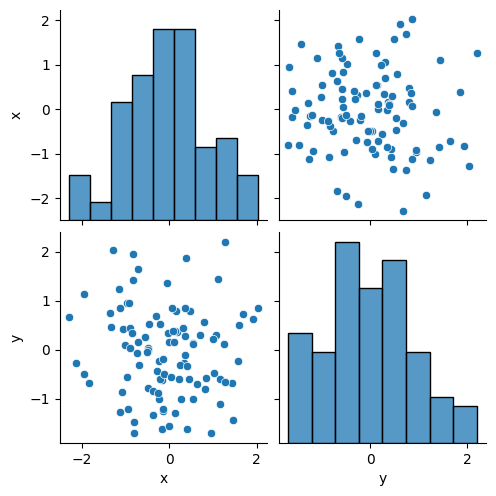

In [ ]:
sns.pairplot(df)

### Exercise 14
Show correlation matrix with Seaborn Heatmap.

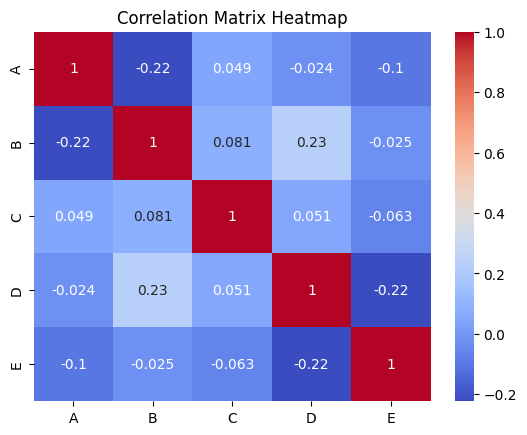

In [ ]:
df = pd.DataFrame(np.random.randn(100, 5), columns=list("ABCDE"))
# df
corr = df.corr()
# corr = df.corr(method="spearman")
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title("Correlation Matrix Heatmap")
plt.show()

### Exercise 15
Check non-linear correlation.

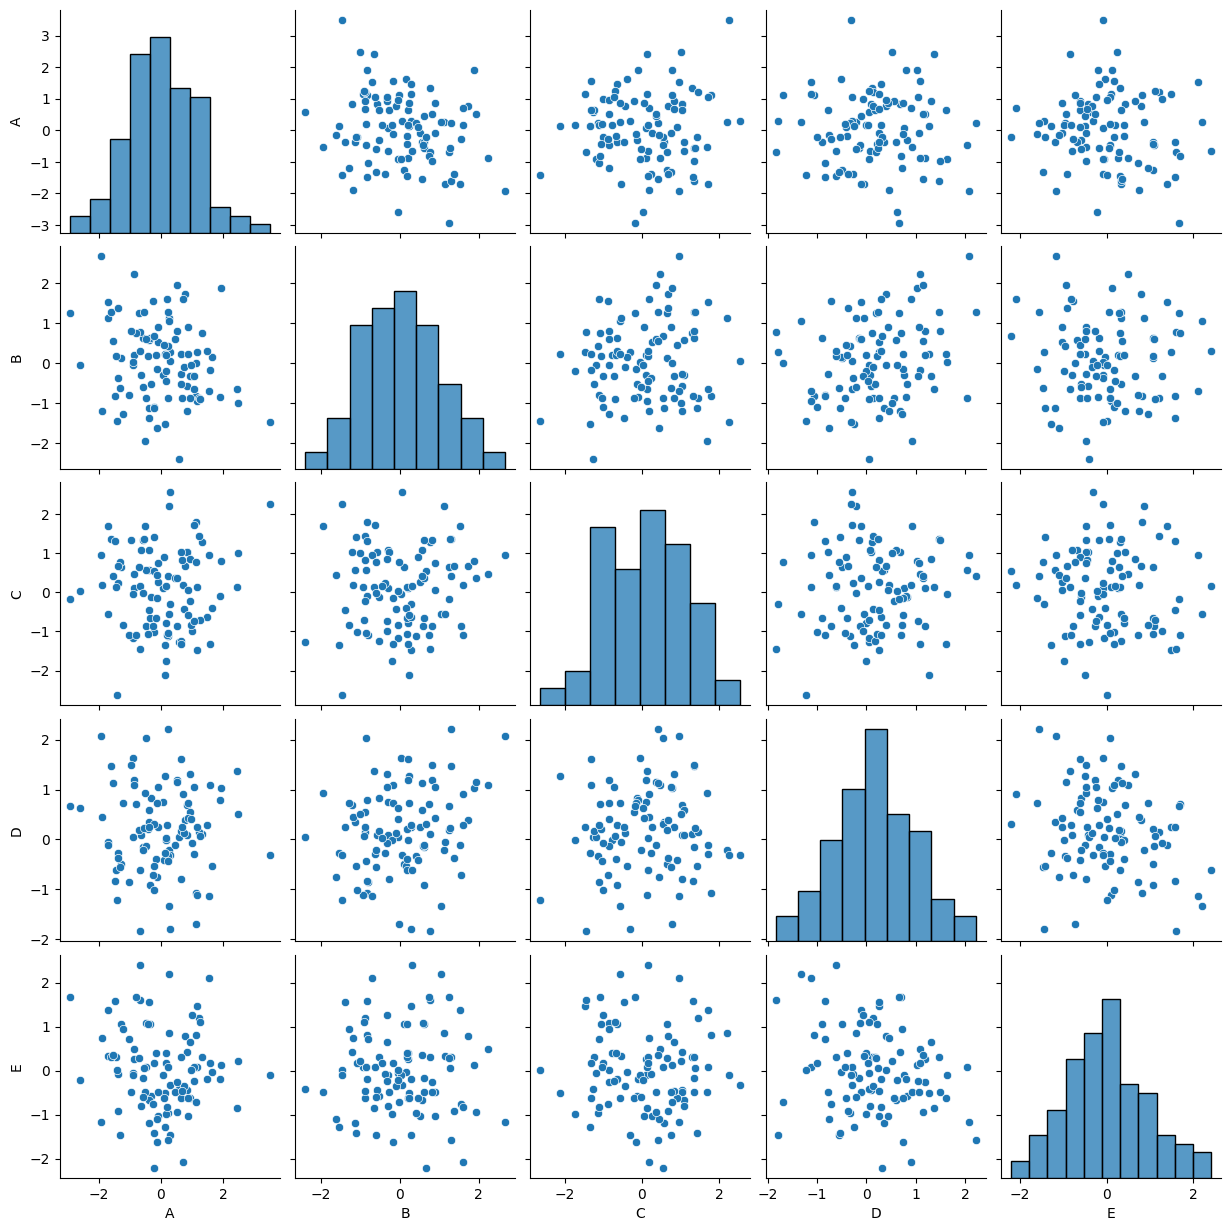

In [ ]:
# check non-linear correlation
sns.pairplot(df)


### Exercise 16
Based on what we have learned above, analyze the `Auto.csv` dataset and search for interesting correlations.

In [ ]:
# loading dataset and displaying first 5 rows
df = pd.read_csv('./Auto.csv')
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin,name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [ ]:
# checking the data types of each column and number of non-null values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397 entries, 0 to 396
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           397 non-null    float64
 1   cylinders     397 non-null    int64  
 2   displacement  397 non-null    float64
 3   horsepower    397 non-null    object 
 4   weight        397 non-null    int64  
 5   acceleration  397 non-null    float64
 6   year          397 non-null    int64  
 7   origin        397 non-null    int64  
 8   name          397 non-null    object 
dtypes: float64(3), int64(4), object(2)
memory usage: 28.0+ KB


In [ ]:
# all columns
df.columns


Index(['mpg', 'cylinders', 'displacement', 'horsepower', 'weight',
       'acceleration', 'year', 'origin', 'name'],
      dtype='object')

In [ ]:
numeric_columns = df.select_dtypes(include=[np.number]).columns.tolist()
numeric_columns

['mpg',
 'cylinders',
 'displacement',
 'weight',
 'acceleration',
 'year',
 'origin']

In [ ]:
# lets check the correlations
df[numeric_columns].corr()

,mpg,cylinders,displacement,weight,acceleration,year,origin
mpg,1.000000,-0.776260,-0.804443,-0.831739,0.422297,0.581469,0.563698
cylinders,-0.776260,1.000000,0.950920,0.897017,-0.504061,-0.346717,-0.564972
displacement,-0.804443,0.950920,1.000000,0.933104,-0.544162,-0.369804,-0.610664
weight,-0.831739,0.897017,0.933104,1.000000,-0.419502,-0.307900,-0.581265
acceleration,0.422297,-0.504061,-0.544162,-0.419502,1.000000,0.282901,0.210084
year,0.581469,-0.346717,-0.369804,-0.307900,0.282901,1.000000,0.184314
origin,0.563698,-0.564972,-0.610664,-0.581265,0.210084,0.184314,1.000000


<Axes: >

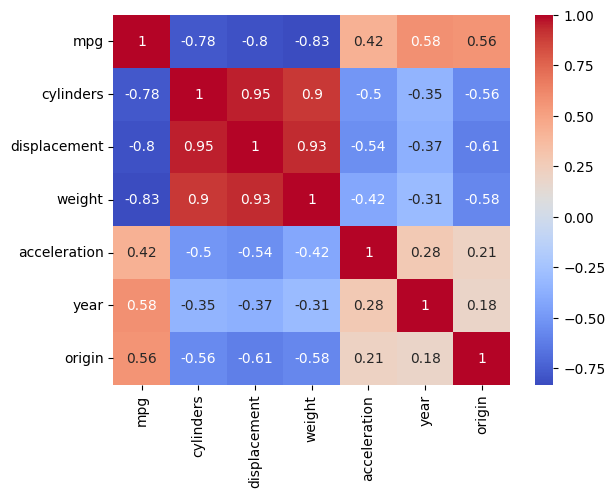

In [ ]:
# visualizing the correlation matrix makes easier to understand
sns.heatmap(df[numeric_columns].corr(), annot=True, cmap='coolwarm')

### Some interesting correlations tha twe can see are:

<Axes: xlabel='weight', ylabel='cylinders'>

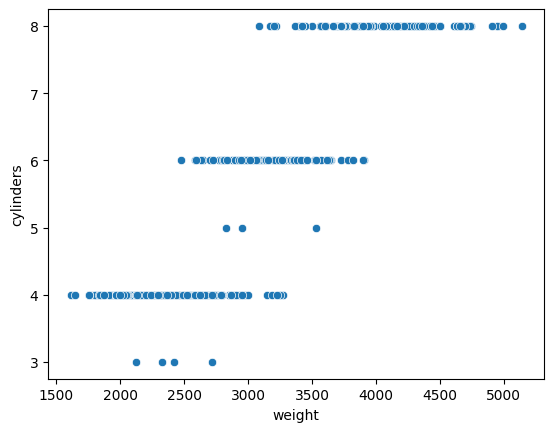

In [ ]:
# correlation between weight and cylinders
sns.scatterplot(data=df, x='weight', y='cylinders')

<Axes: xlabel='cylinders', ylabel='displacement'>

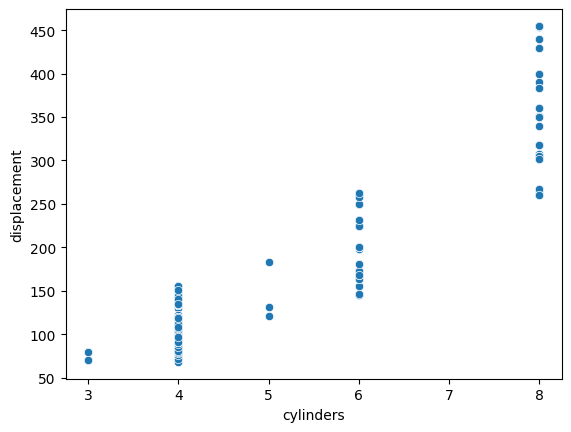

In [ ]:
# correlation between cylinders and displacement
sns.scatterplot(data=df, x='cylinders', y='displacement')

<Axes: xlabel='mpg', ylabel='displacement'>

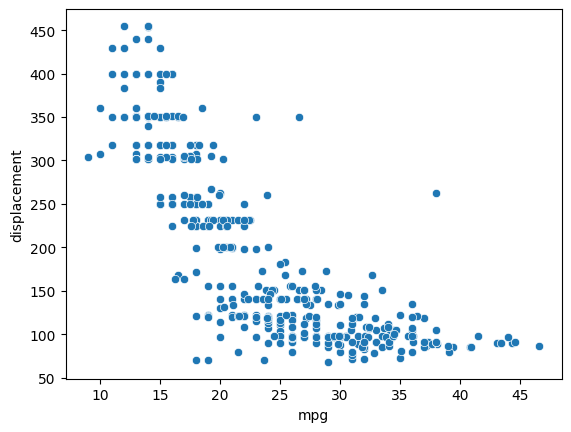

In [ ]:
# correlation between mpg and displacement
sns.scatterplot(data=df, x='mpg', y='displacement')

<Axes: xlabel='horsepower', ylabel='mpg'>

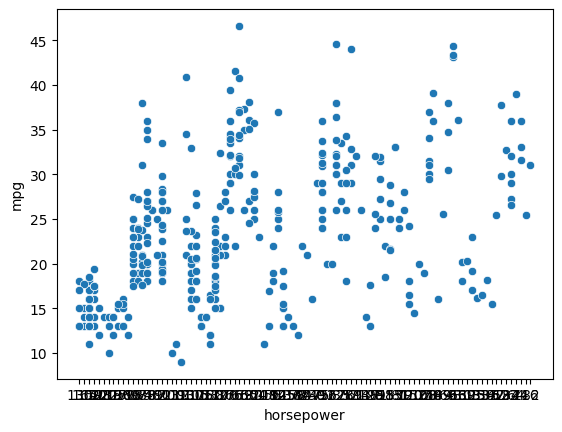

In [ ]:
# correlation between horsepower and mpg
sns.scatterplot(data=df, x='horsepower', y='mpg')

In [ ]:
# but horsepower have some problems - we can see that it is supposed to be a numerical column but it has object dtype
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397 entries, 0 to 396
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           397 non-null    float64
 1   cylinders     397 non-null    int64  
 2   displacement  397 non-null    float64
 3   horsepower    397 non-null    object 
 4   weight        397 non-null    int64  
 5   acceleration  397 non-null    float64
 6   year          397 non-null    int64  
 7   origin        397 non-null    int64  
 8   name          397 non-null    object 
dtypes: float64(3), int64(4), object(2)
memory usage: 28.0+ KB


In [ ]:
df['horsepower'].head()

,horsepower
0,130
1,165
2,150
3,150
4,140


In [ ]:
# lets check for non-numeric values in horsepower
df['horsepower'].unique()

array(['130', '165', '150', '140', '198', '220', '215', '225', '190',
       '170', '160', '95', '97', '85', '88', '46', '87', '90', '113',
       '200', '210', '193', '?', '100', '105', '175', '153', '180', '110',
       '72', '86', '70', '76', '65', '69', '60', '80', '54', '208', '155',
       '112', '92', '145', '137', '158', '167', '94', '107', '230', '49',
       '75', '91', '122', '67', '83', '78', '52', '61', '93', '148',
       '129', '96', '71', '98', '115', '53', '81', '79', '120', '152',
       '102', '108', '68', '58', '149', '89', '63', '48', '66', '139',
       '103', '125', '133', '138', '135', '142', '77', '62', '132', '84',
       '64', '74', '116', '82'], dtype=object)

In [ ]:
# notice the '?' - we have a good eye to spot such issues bt it could be hard to spot in a large dataset
# so lets create a function to spot non-numeric values in a column
def find_non_numeric_values(series):
    non_numeric = []
    for value in series:
        try:
            float(value)
        except ValueError:
            non_numeric.append(value)
    return set(non_numeric)

find_non_numeric_values(df['horsepower'])

{'?'}

In [ ]:
# lets check how many problematic values we have
df[df['horsepower'] == '?']

,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin,name
32,25.0,4,98.0,?,2046,19.0,71,1,ford pinto
126,21.0,6,200.0,?,2875,17.0,74,1,ford maverick
330,40.9,4,85.0,?,1835,17.3,80,2,renault lecar deluxe
336,23.6,4,140.0,?,2905,14.3,80,1,ford mustang cobra
354,34.5,4,100.0,?,2320,15.8,81,2,renault 18i


In [ ]:
print(f'Number of problematic values: {len(df[df["horsepower"] == "?"])}')

Number of problematic values: 5


In [ ]:
# lets find the median of horsepower excluding the problematic values
df[df['horsepower'] != '?']['horsepower'].astype(float).median()

93.5

In [ ]:
# now we can replace the problematic values but the strategy depends on the context
df['horsepower'] = df['horsepower'].replace('?', 93.5)

In [ ]:
# lets check if we have any problematic values left
df[df['horsepower'] == '?']

,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin,name


In [ ]:
# now lets check the dtype of horsepower
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397 entries, 0 to 396
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           397 non-null    float64
 1   cylinders     397 non-null    int64  
 2   displacement  397 non-null    float64
 3   horsepower    397 non-null    object 
 4   weight        397 non-null    int64  
 5   acceleration  397 non-null    float64
 6   year          397 non-null    int64  
 7   origin        397 non-null    int64  
 8   name          397 non-null    object 
dtypes: float64(3), int64(4), object(2)
memory usage: 28.0+ KB


In [ ]:
# lets convert horsepower to numeric

# this is one way of doing it
#df['horsepower'] = pd.to_numeric(df['horsepower'])

# this is another way of doing it
df['horsepower'] = df['horsepower'].astype(float)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397 entries, 0 to 396
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           397 non-null    float64
 1   cylinders     397 non-null    int64  
 2   displacement  397 non-null    float64
 3   horsepower    397 non-null    float64
 4   weight        397 non-null    int64  
 5   acceleration  397 non-null    float64
 6   year          397 non-null    int64  
 7   origin        397 non-null    int64  
 8   name          397 non-null    object 
dtypes: float64(4), int64(4), object(1)
memory usage: 28.0+ KB


In [ ]:
df[['mpg', 'horsepower']].corr()

,mpg,horsepower
mpg,1.000000,-0.773582
horsepower,-0.773582,1.000000


<Axes: xlabel='horsepower', ylabel='mpg'>

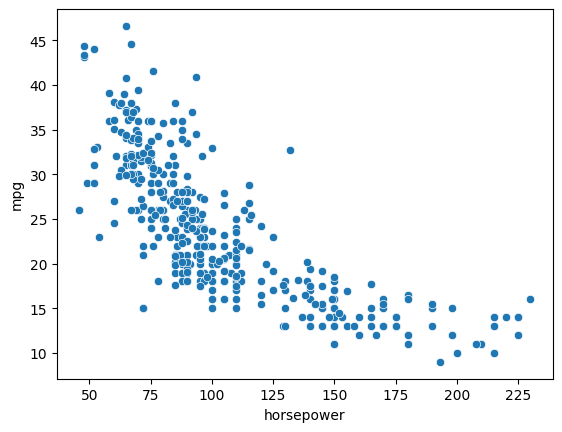

In [ ]:
# now lets check the correlation between horsepower and mpg again
sns.scatterplot(data=df, x='horsepower', y='mpg')

In [ ]:
# as we can see the correlation is much clearer now
# it is important to always check the data types of the columns before doing any analysis
# scatter plots are very useful to visualize correlations between two numerical variables

---

## Part 3 - Reinforcement exercises

Practise descriptive statistics, filtering, visualisation, and correlation using `Auto.csv`. Complete R-01 to R-10 in order and write a short interpretation for each exercise.

Run the setup first. This section uses separate variables and does not depend on answers from earlier sections. In Colab, upload `Auto.csv` before running the setup.

`mpg` is fuel economy in miles per gallon (higher is better), `horsepower` measures engine power, and `weight` is vehicle weight in pounds. `origin` contains category codes, not quantitative measurements. The setup recognises `?` as missing and removes rows missing any of the three measurements used here. Conclusions refer to the retained sample.

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

csv_path = Path("Auto.csv")
if not csv_path.is_file():
    csv_path = Path("Week_4") / "Auto.csv"
if not csv_path.is_file():
    raise FileNotFoundError("Place Auto.csv beside the notebook or run from the repository root.")
auto_raw = pd.read_csv(csv_path, na_values="?")
auto_ref = auto_raw.dropna(subset=["mpg", "horsepower", "weight"]).copy()
print(f"Rows loaded: {len(auto_raw)}; rows retained: {len(auto_ref)}")

Rows loaded: 397; rows retained: 392


### R-01 - Summarising fuel economy

For `mpg`, calculate the mean, median, minimum, maximum, range, sample variance, and sample standard deviation (use Pandas defaults, `ddof=1`). Which measures describe centre and which describe dispersion?

In [ ]:
mpg_summary = auto_ref["mpg"].agg(["mean", "median", "min", "max", "var", "std"])
mpg_summary["range"] = auto_ref["mpg"].max() - auto_ref["mpg"].min()
print(mpg_summary)

mean      23.445918
median    22.750000
min        9.000000
max       46.600000
var       60.918142
std        7.805007
range     37.600000
Name: mpg, dtype: float64


**Interpretation:** Mean and median describe centre. Range, variance, and standard deviation describe dispersion; minimum and maximum mark the observed limits.

### R-02 - Quartiles and filtering

Calculate Q1, Q2, Q3, and the IQR of `mpg`. Select cars with `mpg` strictly above Q3 and `horsepower` below its median. Show only `name`, `mpg`, and `horsepower`, and print the number of matching cars.

In [ ]:
mpg_quartiles = auto_ref["mpg"].quantile([0.25, 0.5, 0.75])
print(mpg_quartiles)
print("IQR:", mpg_quartiles.loc[0.75] - mpg_quartiles.loc[0.25])
selected_cars = auto_ref.loc[
    (auto_ref["mpg"] > mpg_quartiles.loc[0.75])
    & (auto_ref["horsepower"] < auto_ref["horsepower"].median()),
    ["name", "mpg", "horsepower"]
]
print("Matching cars:", len(selected_cars))
print(selected_cars)

0.25    17.00
0.50    22.75
0.75    29.00
Name: mpg, dtype: float64
IQR: 12.0
Matching cars: 92
                                  name   mpg  horsepower
51                         peugeot 304  30.0        70.0
52                           fiat 124b  30.0        76.0
53                 toyota corolla 1200  31.0        65.0
54                         datsun 1200  35.0        69.0
129                        datsun b210  31.0        67.0
..                                 ...   ...         ...
386  oldsmobile cutlass ciera (diesel)  38.0        85.0
390                  dodge charger 2.2  36.0        84.0
393                          vw pickup  44.0        52.0
394                      dodge rampage  32.0        84.0
396                         chevy s-10  31.0        82.0

[92 rows x 3 columns]


**Interpretation:** This combines relatively high fuel economy and below-median engine power within the sample. Q2 is the median and the IQR describes the spread of the middle 50%.

### R-03 - Inspecting a distribution

Create a histogram of `mpg` with 12 bins and a boxplot of the same variable. Add titles and axis labels. Describe the shape and any points beyond the boxplot whiskers. Does such a point necessarily indicate a data error?

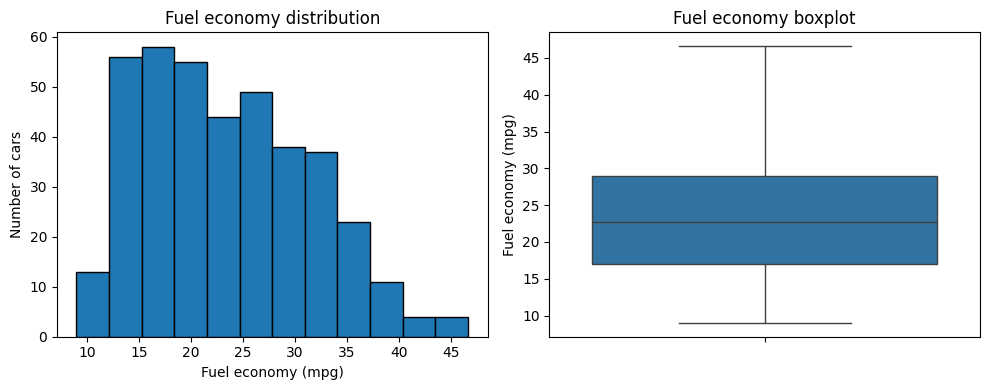

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(auto_ref["mpg"], bins=12, edgecolor="black")
axes[0].set(title="Fuel economy distribution", xlabel="Fuel economy (mpg)", ylabel="Number of cars")
sns.boxplot(data=auto_ref, y="mpg", ax=axes[1])
axes[1].set(title="Fuel economy boxplot", ylabel="Fuel economy (mpg)")
plt.tight_layout()
plt.show()

**Interpretation:** Look for asymmetry and concentrations in the histogram. Under the default boxplot rule, points beyond the whiskers fall more than 1.5 IQR below Q1 or above Q3. Such values warrant inspection but are not automatically errors.

### R-04 - Creating categories

Use `np.where` to add `economy_group`: `At or above median` when `mpg` is at least its median, and `Below median` otherwise. Display category frequencies and draw a labelled bar chart. Explain why the two counts need not be equal.

economy_group
Below median          196
At or above median    196
Name: count, dtype: int64


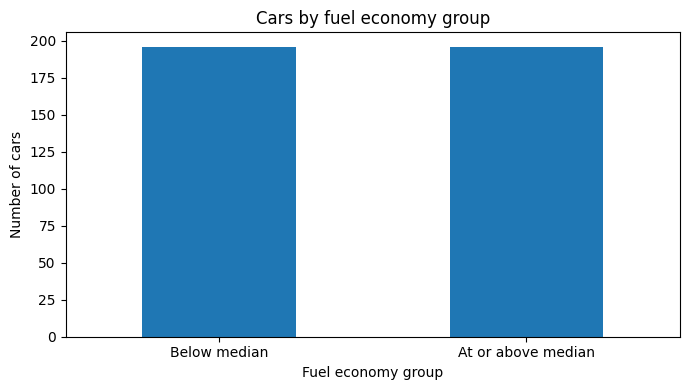

In [ ]:
auto_ref["economy_group"] = np.where(
    auto_ref["mpg"] >= auto_ref["mpg"].median(),
    "At or above median", "Below median"
)
economy_counts = auto_ref["economy_group"].value_counts()
print(economy_counts)
economy_counts.plot.bar(rot=0, figsize=(7, 4))
plt.title("Cars by fuel economy group")
plt.xlabel("Fuel economy group")
plt.ylabel("Number of cars")
plt.tight_layout()
plt.show()

**Interpretation:** All repeated values equal to the median enter the same group. The median therefore does not guarantee equal category counts.

### R-05 - Visualising an association

Draw a scatter plot with `weight` on the horizontal axis and `mpg` on the vertical axis. Include a linear trend line using `sns.regplot`. Add labels and a title. Describe the direction and how closely the points follow a straight line.

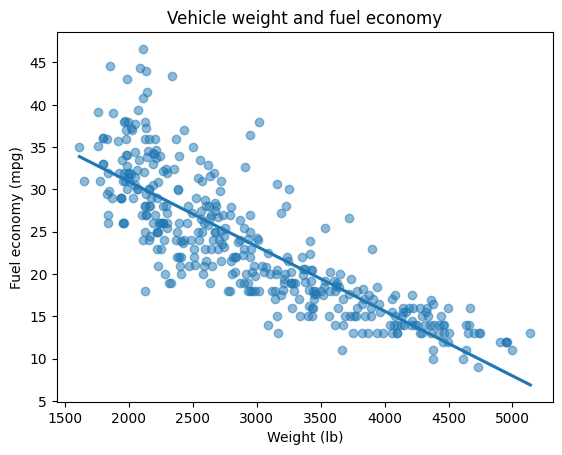

In [ ]:
sns.regplot(data=auto_ref, x="weight", y="mpg", ci=None, scatter_kws={"alpha": 0.5})
plt.title("Vehicle weight and fuel economy")
plt.xlabel("Weight (lb)")
plt.ylabel("Fuel economy (mpg)")
plt.show()

**Interpretation:** The association is negative: heavier cars generally have lower mpg. Scatter and curvature show that a straight line does not describe every detail.

### R-06 - Quantifying the association

Calculate Pearson's coefficient and p-value for `weight` and `mpg`. Interpret the sign and magnitude. At significance level 0.05, what does the p-value indicate about the null hypothesis of zero population Pearson correlation? Does this prove causation?

In [ ]:
weight_r, weight_p = stats.pearsonr(auto_ref["weight"], auto_ref["mpg"])
print(f"Pearson r: {weight_r:.3f}")
print(f"p-value: {weight_p:.3g}")

Pearson r: -0.832
p-value: 6.02e-102


**Interpretation:** The coefficient is approximately -0.832, a strong negative linear association. The p-value is below 0.05, providing evidence against zero population Pearson correlation under the test assumptions. It is not the probability that the null hypothesis is true. Sampling and independence assumptions matter, and observational association alone does not establish causation.

### R-07 - Comparing several variables

Calculate the Pearson correlation matrix for `mpg`, `horsepower`, and `weight`. Draw an annotated heatmap with a colour scale from -1 to 1 centred at 0. Ignoring the diagonal, identify the pair with the largest absolute correlation. Explain the diagonal entries.

                 mpg  horsepower    weight
mpg         1.000000   -0.778427 -0.832244
horsepower -0.778427    1.000000  0.864538
weight     -0.832244    0.864538  1.000000


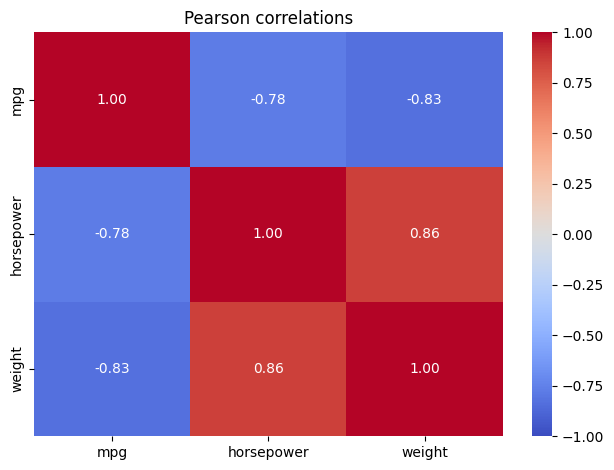

In [ ]:
corr_ref = auto_ref[["mpg", "horsepower", "weight"]].corr(method="pearson")
print(corr_ref)
sns.heatmap(corr_ref, annot=True, fmt=".2f", vmin=-1, vmax=1, center=0, cmap="coolwarm")
plt.title("Pearson correlations")
plt.tight_layout()
plt.show()

**Interpretation:** Horsepower and weight have the largest absolute correlation (about +0.865). Each nonconstant variable is perfectly correlated with itself, producing 1 on the diagonal.

### R-08 - Looking at categories

Draw a scatter plot with `horsepower` on the horizontal axis and `mpg` on the vertical axis, colouring points by `origin`. Treat origin codes as categories and include a legend. Describe overlap or differences between groups. Why should we avoid Pearson correlation with numeric origin codes?

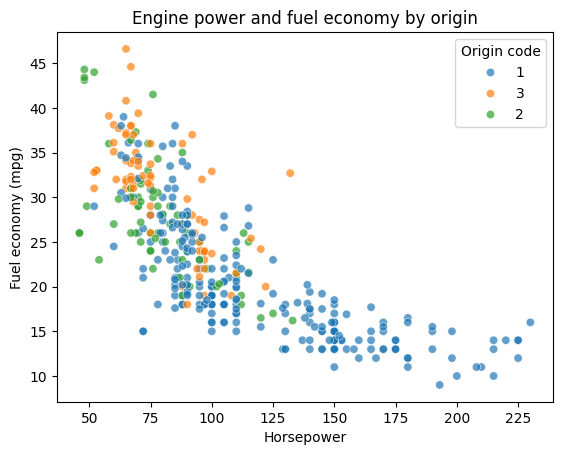

In [ ]:
sns.scatterplot(data=auto_ref, x="horsepower", y="mpg",
                hue=auto_ref["origin"].astype(str), alpha=0.7)
plt.title("Engine power and fuel economy by origin")
plt.xlabel("Horsepower")
plt.ylabel("Fuel economy (mpg)")
plt.legend(title="Origin code")
plt.show()

**Interpretation:** Compare the ranges and overlap rather than assuming completely separate groups. Origin codes are labels with no meaningful numeric spacing; recoding them would change a Pearson coefficient.

### R-09 - Pearson and Spearman

Calculate Pearson and Spearman correlations between `horsepower` and `mpg`. Compare their signs and absolute magnitudes. Use the preceding scatter plot to support your interpretation, and explain what each coefficient measures.

In [ ]:
hp_pearson, _ = stats.pearsonr(auto_ref["horsepower"], auto_ref["mpg"])
hp_spearman, _ = stats.spearmanr(auto_ref["horsepower"], auto_ref["mpg"])
print(f"Pearson: {hp_pearson:.3f}")
print(f"Spearman: {hp_spearman:.3f}")

Pearson: -0.778
Spearman: -0.854


**Interpretation:** Both are negative. Pearson measures linear association; Spearman measures monotonic association through ranks. The stronger absolute Spearman coefficient is consistent with a decreasing relationship that is not perfectly linear. Use the plot as well as the coefficients.

### R-10 - Challenge: a relationship hidden by correlation

Create `x_ref = np.linspace(-10, 10, 101)` and `y_ref = x_ref**2` without noise. Plot the points and calculate Pearson and Spearman correlations. Repeat both calculations for `x_ref >= 0`. Explain why full-range coefficients can be near zero despite a deterministic relationship and why the nonnegative subset behaves differently.

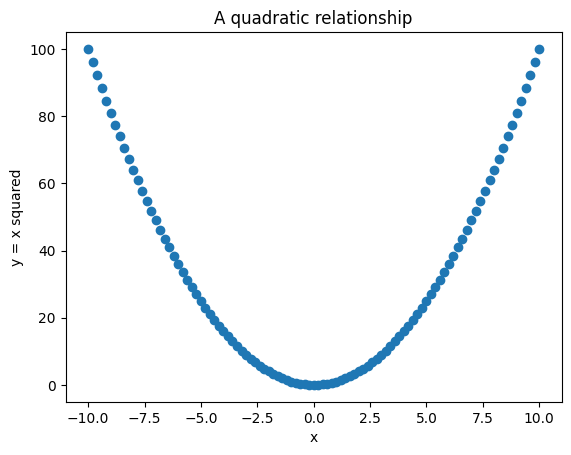

Full range Pearson: 1.8735013540549517e-16
Full range Spearman: 0.009225822995360945
Nonnegative Pearson: 0.9670739693782717
Nonnegative Spearman: 0.9999999999999999


In [ ]:
x_ref = np.linspace(-10, 10, 101)
y_ref = x_ref**2
plt.scatter(x_ref, y_ref)
plt.title("A quadratic relationship")
plt.xlabel("x")
plt.ylabel("y = x squared")
plt.show()
print("Full range Pearson:", stats.pearsonr(x_ref, y_ref)[0])
print("Full range Spearman:", stats.spearmanr(x_ref, y_ref)[0])
nonnegative = x_ref >= 0
print("Nonnegative Pearson:", stats.pearsonr(x_ref[nonnegative], y_ref[nonnegative])[0])
print("Nonnegative Spearman:", stats.spearmanr(x_ref[nonnegative], y_ref[nonnegative])[0])

**Interpretation:** Across the symmetric full range, the curve decreases then increases: it is neither linear nor monotonic, so both coefficients are near zero. The nonnegative subset is strictly increasing, giving Spearman 1. Pearson is positive but below 1 because the relationship is curved. Zero correlation does not imply no relationship.